In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn.objects as so

In [4]:
onda = pd.read_csv('volumen_vehicular_2024_detalle_semanal.csv')
onda.head()

,fecha_conteo,anio_conteo,mes_conteo,franja_horaria_conteo,cuarto_hora_conteo,dia_semana_conteo,ubicacion_conteo,longitud_conteo,latitud_conteo,comuna_conteo,cantidad_carriles_via_conteos,especificacion_via_conteos,tipo_circulacion_via_conteos,sentido_circulacion_conteo,tipo_vehiculo,conteo_vehiculos
0,2024-03-02,2024,3,12,3,SAB,RIVADAVIA AV. 4987,-58.436080,-34.618047,Comuna 6,4.0,calle_avenida,única,oeste,Colectivo,10
1,2024-03-02,2024,3,14,2,SAB,CORDOBA AV. 1147,-58.383217,-34.599039,Comuna 1,NaN,Carriles Exclusivos,única,oeste,Colectivo,5
2,2024-03-02,2024,3,13,3,SAB,RIVADAVIA AV. 4987,-58.436080,-34.618047,Comuna 6,4.0,calle_avenida,única,oeste,Colectivo,13
3,2024-03-02,2024,3,4,4,SAB,ENTRE RIOS AV. 926,-58.391557,-34.619431,Comuna 1,NaN,Carriles Exclusivos,única,norte,Colectivo,1
4,2024-03-02,2024,3,7,2,SAB,CORDOBA AV. 1749,-58.392148,-34.599512,Comuna 2,NaN,Carriles Exclusivos,única,oeste,Colectivo,6


In [31]:
cordoba = onda[onda['ubicacion_conteo'] == 'CORDOBA AV. 4471']
cordoba

,fecha_conteo,anio_conteo,mes_conteo,franja_horaria_conteo,cuarto_hora_conteo,dia_semana_conteo,ubicacion_conteo,longitud_conteo,latitud_conteo,comuna_conteo,cantidad_carriles_via_conteos,especificacion_via_conteos,tipo_circulacion_via_conteos,sentido_circulacion_conteo,tipo_vehiculo,conteo_vehiculos
279,2024-03-02,2024,3,13,1,SAB,CORDOBA AV. 4471,-58.428774,-34.594989,Comuna 14,4.0,calle_avenida,única,oeste,Colectivo,6
313,2024-03-02,2024,3,15,1,SAB,CORDOBA AV. 4471,-58.428774,-34.594989,Comuna 14,4.0,calle_avenida,única,oeste,Colectivo,7
325,2024-03-02,2024,3,16,1,SAB,CORDOBA AV. 4471,-58.428774,-34.594989,Comuna 14,4.0,calle_avenida,única,oeste,Colectivo,5
348,2024-03-02,2024,3,13,3,SAB,CORDOBA AV. 4471,-58.428774,-34.594989,Comuna 14,4.0,calle_avenida,única,oeste,Colectivo,9
365,2024-03-02,2024,3,9,1,SAB,CORDOBA AV. 4471,-58.428774,-34.594989,Comuna 14,4.0,calle_avenida,única,oeste,Colectivo,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
231076,2024-03-08,2024,3,14,4,VIE,CORDOBA AV. 4471,-58.428774,-34.594989,Comuna 14,4.0,calle_avenida,única,oeste,Otros,1
231087,2024-03-08,2024,3,13,2,VIE,CORDOBA AV. 4471,-58.428774,-34.594989,Comuna 14,4.0,calle_avenida,única,oeste,Otros,1
231096,2024-03-08,2024,3,13,3,VIE,CORDOBA AV. 4471,-58.428774,-34.594989,Comuna 14,4.0,calle_avenida,única,oeste,Otros,1
231121,2024-03-08,2024,3,16,2,VIE,CORDOBA AV. 4471,-58.428774,-34.594989,Comuna 14,4.0,calle_avenida,única,oeste,Otros,2


In [32]:
circuito = {
    'CORDOBA AV. 1147':    'oeste',
    'CORDOBA AV. 1431':    'oeste',
    'CORDOBA AV. 1749':    'oeste',
    'CORDOBA AV. 1980':    'oeste',

    'CORDOBA AV. 2149':    'oeste',
    'CORDOBA AV. 2523':    'oeste',
    'CORDOBA AV. 2801':    'oeste',

    'CORDOBA AV. 3143':    'oeste',
    'CORDOBA AV. 3329':    'oeste',
    'CORDOBA AV. 3647':    'oeste',

    'CORDOBA AV. 4471':    'oeste',
    'CORDOBA AV. 4570':    'oeste',
    
    


}
dias = ['VIE', 'LUN', 'MAR', 'MIE', 'JUE']

onda_8am = onda[
    (onda['ubicacion_conteo'].map(circuito) == onda['sentido_circulacion_conteo']) &
    (onda['franja_horaria_conteo'] == 8) &
    onda['dia_semana_conteo'].isin(dias)
].copy()

In [34]:
por_dia = (onda_8am.groupby(['ubicacion_conteo', 'fecha_conteo','sentido_circulacion_conteo','cuarto_hora_conteo'])['conteo_vehiculos'].sum())

In [35]:
prom_onda_8am = (por_dia.groupby(['ubicacion_conteo','sentido_circulacion_conteo', 'cuarto_hora_conteo']).mean().reset_index(name='vehiculos_promedio'))
prom_onda_8am

,ubicacion_conteo,sentido_circulacion_conteo,cuarto_hora_conteo,vehiculos_promedio
0,CORDOBA AV. 1147,oeste,1,25.000000
1,CORDOBA AV. 1147,oeste,2,28.000000
2,CORDOBA AV. 1147,oeste,3,27.200000
3,CORDOBA AV. 1147,oeste,4,39.000000
4,CORDOBA AV. 1431,oeste,1,78.600000
5,CORDOBA AV. 1431,oeste,2,75.600000
6,CORDOBA AV. 1431,oeste,3,80.800000
7,CORDOBA AV. 1431,oeste,4,93.000000
8,CORDOBA AV. 1749,oeste,1,14.800000
9,CORDOBA AV. 1749,oeste,2,18.000000


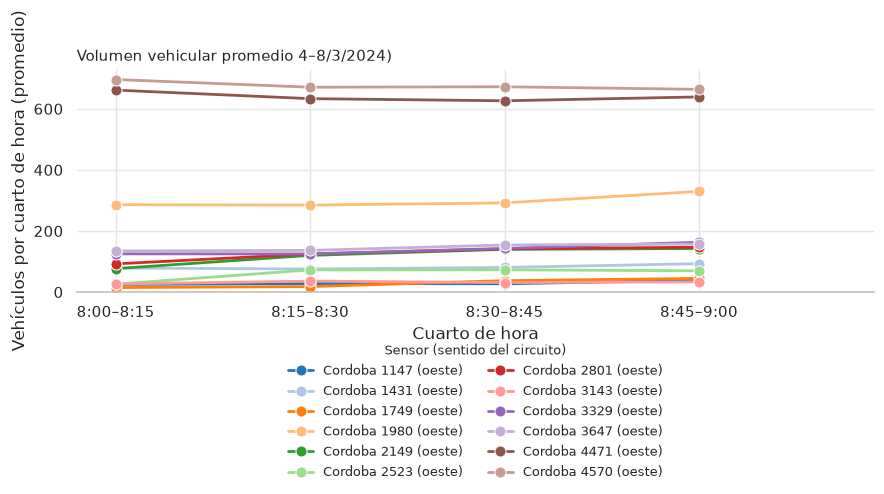

In [ ]:
cuartos = {1: '8:00–8:15', 2: '8:15–8:30', 3: '8:30–8:45', 4: '8:45–9:00'}
prom_onda_8am['cuarto'] = prom_onda_8am['cuarto_hora_conteo'].map(cuartos)
prom_onda_8am['sensor'] = (prom_onda_8am['ubicacion_conteo'].str.replace(' AV.', '', regex=False).str.title() + ' (' + prom_onda_8am['sentido_circulacion_conteo'] + ')')

orden = ['Cordoba 1147 (oeste)', 'Cordoba 1431 (oeste)', 'Cordoba 1749 (oeste)', 'Cordoba 1980 (oeste)', 'Cordoba 2149 (oeste)','Cordoba 2523 (oeste)','Cordoba 2801 (oeste)', 'Cordoba 3143 (oeste)', 'Cordoba 3329 (oeste)', 'Cordoba 3647 (oeste)', 'Cordoba 4471 (oeste)', 'Cordoba 4570 (oeste)']

colores = dict(zip(orden, sns.color_palette('tab20', len(orden))))

sns.set_theme(style='whitegrid', rc={'grid.color': '#e5e5e5', 'axes.edgecolor': "#cac1c1"})
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=prom_onda_8am, x='cuarto', y='vehiculos_promedio', hue='sensor', hue_order=orden, palette=colores, marker='o', markersize=8, linewidth=2, sort=False, ax=ax)

for s in orden:
    y = prom_onda_8am.loc[(prom_onda_8am['cuarto_hora_conteo'] ==4), 'vehiculos_promedio'].iloc[0]

ax.set_title('Volumen vehicular promedio 4–8/3/2024)', loc='left', fontsize=11)
ax.set_xlabel('Cuarto de hora')
ax.set_ylabel('Vehículos por cuarto de hora (promedio)')
ax.set_ylim(0, None)
ax.set_xlim(-0.2, 3.9)
ax.legend(title='Sensor (sentido del circuito)', frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9, title_fontsize=9)
sns.despine(left=True)
plt.tight_layout()
plt.show()

In [41]:
semaforos_onda = pd.read_csv('semaforos_cordoba_oeste.csv')
semaforos_onda.head()

,orden,cruce_con,distancia_desde_inicio_m,distancia_al_anterior_m
0,1,Libertad,75.2,75.2
1,2,Talcahuano,206.0,130.8
2,3,Uruguay,329.5,123.5
3,4,Paraná,455.7,126.2
4,5,Montevideo,596.3,140.7
